# FRAUD TRANSACTIONS ANALYSIS

In [2]:
# Load the finance transactions fraud dataset
import pandas as pd
data = pd.read_csv(r'C:\Users\HP\Documents\TOP 10 INDUSTRIES\fraud_detection_project\data\01_finance_transactions_fraud.csv')

In [3]:
# View the data
data.head(8)

,transaction_id,customer_id,timestamp,amount_kes,merchant_category,channel,country,new_device,is_fraud
0,TX0000001,3154,2025-01-01 00:01:34.000000000,648.08,Utilities,Bank Transfer,KE,0,0
1,TX0000002,3946,2025-01-01 00:55:19.000000000,1332.23,Airtime,M-Pesa,KE,0,0
2,TX0000003,4734,2025-01-01 01:19:24.000000000,329.61,Fuel,ATM,KE,0,0
3,TX0000004,4052,2025-01-01 01:39:02.000000000,4093.17,Restaurants,M-Pesa,KE,0,1
4,TX0000005,2856,2025-01-01 01:41:10.000000000,2564.41,Groceries,Card Online,KE,0,0
5,TX0000006,3612,2025-01-01 01:42:52.000000000,788.43,Utilities,M-Pesa,KE,0,0
6,TX0000007,3191,2025-01-01 02:17:39.000000000,475.42,Utilities,ATM,US,0,0
7,TX0000008,4052,2025-01-01 02:35:27.992152443,6690.51,Electronics,Bank Transfer,KE,0,1


In [3]:
# data types
data.dtypes

transaction_id           str
customer_id            int64
timestamp                str
amount_kes           float64
merchant_category        str
channel                  str
country                  str
new_device             int64
is_fraud               int64
dtype: object

In [5]:
# convert timestamp data type to date/time
data["timestamp"] = pd.to_datetime(data["timestamp"],errors="coerce")

In [7]:
# check its changed
data.dtypes

transaction_id                  str
customer_id                   int64
timestamp            datetime64[ns]
amount_kes                  float64
merchant_category               str
channel                         str
country                         str
new_device                    int64
is_fraud                      int64
dtype: object

In [9]:
# put transactions in chronological order
data = data.sort_values("timestamp").reset_index(drop=True)

In [10]:
data.head()

,transaction_id,customer_id,timestamp,amount_kes,merchant_category,channel,country,new_device,is_fraud
0,TX0000001,3154,2025-01-01 00:01:34,648.08,Utilities,Bank Transfer,KE,0,0
1,TX0000002,3946,2025-01-01 00:55:19,1332.23,Airtime,M-Pesa,KE,0,0
2,TX0000003,4734,2025-01-01 01:19:24,329.61,Fuel,ATM,KE,0,0
3,TX0000004,4052,2025-01-01 01:39:02,4093.17,Restaurants,M-Pesa,KE,0,1
4,TX0000005,2856,2025-01-01 01:41:10,2564.41,Groceries,Card Online,KE,0,0


In [11]:
# size of the data
data.shape

# 60000 rows and 9 columns

(60000, 9)

In [12]:
# quality of the data
data.isnull().sum()

# there are no missing values

transaction_id       0
customer_id          0
timestamp            0
amount_kes           0
merchant_category    0
channel              0
country              0
new_device           0
is_fraud             0
dtype: int64

In [13]:
data.duplicated().sum()

# there are no duplicates

np.int64(0)

In [15]:
# first transaction timestamp
data['timestamp'].min()

Timestamp('2025-01-01 00:01:34')

In [16]:
# last transaction timestamp
data['timestamp'].max()

Timestamp('2025-12-31 23:47:11')

In [17]:
# are there duplicate transactions?
data['transaction_id'].duplicated().sum()

# there are no duplicate transactions

np.int64(0)

In [20]:
# fraud transactions
data['is_fraud'].sum()

# there are 720 fraud transactions

np.int64(720)

In [23]:
# fraud rate
fraud_rate = ((data['is_fraud'].sum()) / (data['is_fraud'].count())) * 100
print('fraud rate;',fraud_rate,'%')

fraud rate; 1.2 %


FRAUD RATE BY CHANNEL

In [44]:
# fraud rate by channel(bar graph)
data['channel'].value_counts()

channel
M-Pesa           23714
Card POS         11924
Card Online       9267
Bank Transfer     9091
ATM               6004
Name: count, dtype: int64

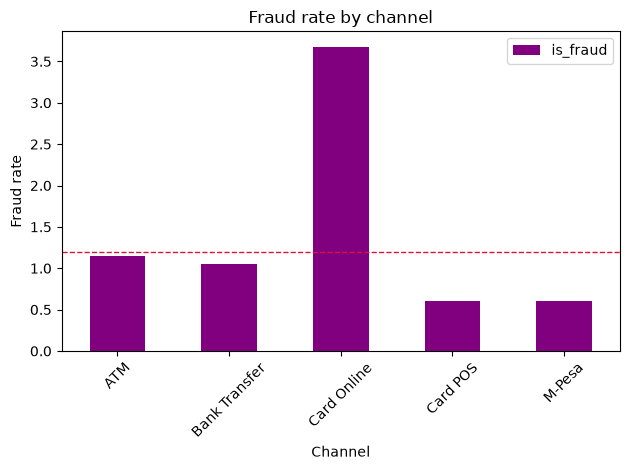

In [55]:
import matplotlib.pyplot as plt
fraud_rate = data['is_fraud'].mean() * 100
channel_fraud_rate = data.groupby('channel')['is_fraud'].mean() * 100
channel_fraud_rate.plot(kind='bar',color='purple')

plt.xlabel('Channel')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by channel')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.axhline(y=fraud_rate, c="crimson", linestyle="--", linewidth=1)
plt.show()

In [66]:
channel_fraud_rate.sort_values(ascending=False)

#Card online has the highest fraud rate of 3.68% way above the average fraud rate of 1.2%

channel
Card Online      3.679724
ATM              1.149234
Bank Transfer    1.055989
Card POS         0.603824
M-Pesa           0.598802
Name: is_fraud, dtype: float64

FRAUD RATE BY HOUR

In [56]:
# extract hour from the timestamp
data['hour'] = pd.to_datetime(data['timestamp']).dt.hour
data['hour']

0         0
1         0
2         1
3         1
4         1
         ..
59995    23
59996    23
59997    23
59998    23
59999    23
Name: hour, Length: 60000, dtype: int32

In [57]:
data.head()

,transaction_id,customer_id,timestamp,amount_kes,merchant_category,channel,country,new_device,is_fraud,hour
0,TX0000001,3154,2025-01-01 00:01:34,648.08,Utilities,Bank Transfer,KE,0,0,0
1,TX0000002,3946,2025-01-01 00:55:19,1332.23,Airtime,M-Pesa,KE,0,0,0
2,TX0000003,4734,2025-01-01 01:19:24,329.61,Fuel,ATM,KE,0,0,1
3,TX0000004,4052,2025-01-01 01:39:02,4093.17,Restaurants,M-Pesa,KE,0,1,1
4,TX0000005,2856,2025-01-01 01:41:10,2564.41,Groceries,Card Online,KE,0,0,1


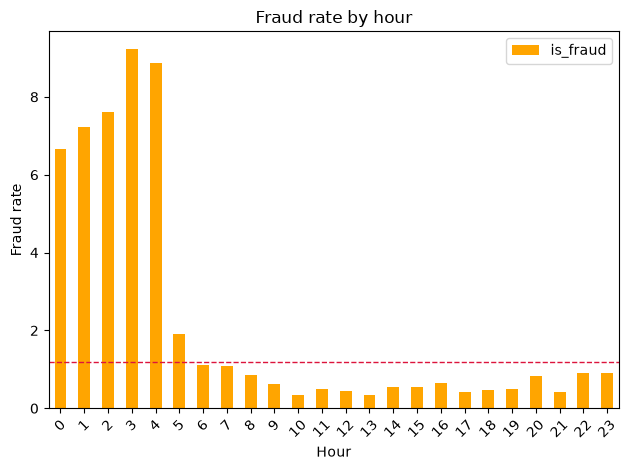

In [59]:
import matplotlib.pyplot as py
fraud_rate = data['is_fraud'].mean() * 100
hour_fraud_rate = data.groupby('hour')['is_fraud'].mean() * 100
hour_fraud_rate.plot(kind='bar',color='orange')

plt.xlabel('Hour')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by hour')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.axhline(y=fraud_rate, c="crimson", linestyle="--", linewidth=1)
plt.show()

In [65]:
# most fraudulent transactions occur in the morning hours from midnight to 5 am, all the hours having very high fraud rates avove he average fraud rate
hour_fraud_rate.sort_values(ascending=False)

hour
3     9.222222
4     8.866442
2     7.613636
1     7.223476
0     6.650831
5     1.897733
6     1.123596
7     1.087304
23    0.916870
22    0.895713
8     0.850126
20    0.820966
16    0.659755
9     0.620915
14    0.544523
15    0.540885
11    0.505849
19    0.505051
18    0.476796
12    0.435053
21    0.422764
17    0.411132
10    0.347991
13    0.340557
Name: is_fraud, dtype: float64

# FRAUD RATE BY COUNTRY

In [60]:
data.head()

,transaction_id,customer_id,timestamp,amount_kes,merchant_category,channel,country,new_device,is_fraud,hour
0,TX0000001,3154,2025-01-01 00:01:34,648.08,Utilities,Bank Transfer,KE,0,0,0
1,TX0000002,3946,2025-01-01 00:55:19,1332.23,Airtime,M-Pesa,KE,0,0,0
2,TX0000003,4734,2025-01-01 01:19:24,329.61,Fuel,ATM,KE,0,0,1
3,TX0000004,4052,2025-01-01 01:39:02,4093.17,Restaurants,M-Pesa,KE,0,1,1
4,TX0000005,2856,2025-01-01 01:41:10,2564.41,Groceries,Card Online,KE,0,0,1


In [61]:
data['country'].unique()

<ArrowStringArray>
['KE', 'US', 'AE', 'UG', 'TZ', 'GB']
Length: 6, dtype: str

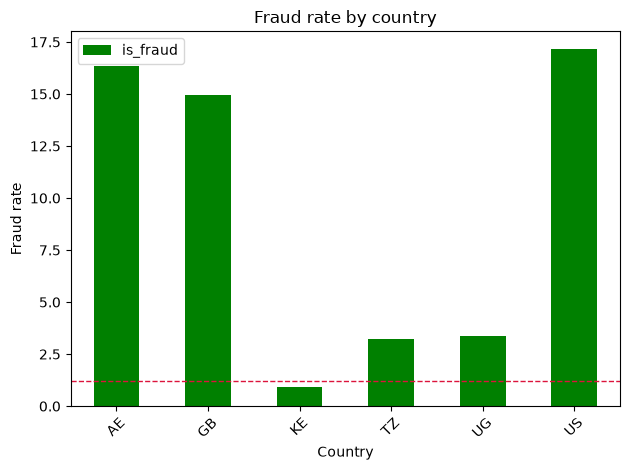

In [62]:
import matplotlib.pyplot as py
fraud_rate = data['is_fraud'].mean() * 100
country_fraud_rate = data.groupby('country')['is_fraud'].mean() *100
country_fraud_rate.plot(kind='bar',color='green')

plt.xlabel('Country')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.axhline(y=fraud_rate, c="crimson", linestyle="--", linewidth=1)
plt.show()

In [64]:
# United Arab Emirates, Great Britain, Tanzania, Uganda and the United States have fraud rates above the average fraud rate of 1.2
country_fraud_rate.sort_values(ascending=False)
# US has the highest fraud rate of 17.15% followed by AE WITH 16.36% AND GB with 14.97%
# KENYA IS THE ONLY CONTRY WITH A FRAUD RATE OF 0.9%, BELOW THE AVERAGE FRAUD RATE OF 1.2

country
US    17.153285
AE    16.355140
GB    14.973262
UG     3.352412
TZ     3.243671
KE     0.928956
Name: is_fraud, dtype: float64

# FRAUD RATE BY MERCHANT CATEGORY

In [67]:
data.head()

,transaction_id,customer_id,timestamp,amount_kes,merchant_category,channel,country,new_device,is_fraud,hour
0,TX0000001,3154,2025-01-01 00:01:34,648.08,Utilities,Bank Transfer,KE,0,0,0
1,TX0000002,3946,2025-01-01 00:55:19,1332.23,Airtime,M-Pesa,KE,0,0,0
2,TX0000003,4734,2025-01-01 01:19:24,329.61,Fuel,ATM,KE,0,0,1
3,TX0000004,4052,2025-01-01 01:39:02,4093.17,Restaurants,M-Pesa,KE,0,1,1
4,TX0000005,2856,2025-01-01 01:41:10,2564.41,Groceries,Card Online,KE,0,0,1


In [68]:
data['merchant_category'].unique()

<ArrowStringArray>
[  'Utilities',     'Airtime',        'Fuel', 'Restaurants',   'Groceries',
 'Electronics',      'Health',     'Betting',      'Travel',   'Transfers']
Length: 10, dtype: str

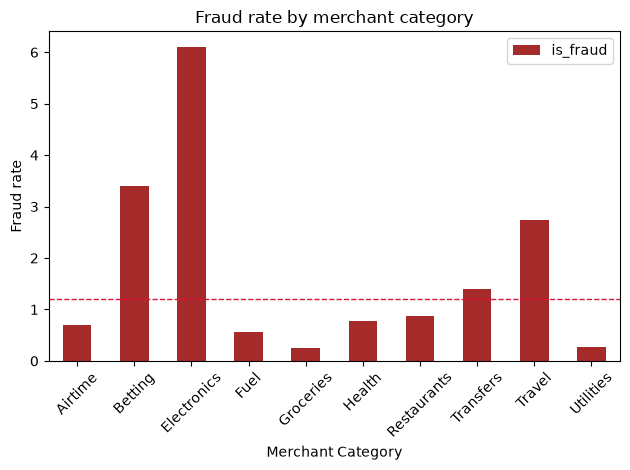

In [69]:
import matplotlib.pyplot as py
fraud_rate = data['is_fraud'].mean() *100
merchant_fraud_rate = data.groupby('merchant_category')['is_fraud'].mean()*100
merchant_fraud_rate.plot(kind='bar',color='brown')

plt.xlabel('Merchant Category')
plt.ylabel('Fraud rate')
plt.title('Fraud rate by merchant category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.axhline(y=fraud_rate, c="crimson", linestyle="--", linewidth=1)
plt.show()

In [70]:
merchant_fraud_rate.sort_values(ascending=False)

# Electronics, Betting, Travel and Transfers are the categories with the most fraudulent transactions above the average fraud rate of 1.2%

merchant_category
Electronics    6.101915
Betting        3.408360
Travel         2.736156
Transfers      1.390135
Restaurants    0.868839
Health         0.766411
Airtime        0.693745
Fuel           0.567234
Utilities      0.267514
Groceries      0.260045
Name: is_fraud, dtype: float64

# FRAUDULENT TRANSACTIONS AMOUNT

In [6]:
fraudulent_transactions_amount = data.loc[data['is_fraud'] == 1, 'amount_kes'].sum()

print('Fraudulent Transactions Amount; Ksh.', fraudulent_transactions_amount)

Fraudulent Transactions Amount; Ksh. 2665780.0
